<a href="https://colab.research.google.com/github/NidaFatima-123/Colab-Projects/blob/main/Fedrated_Medical_Assistat_for_Privacy_Preserving_Clinical_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Federated Medical Research Assistant for Privacy-Preserving Clinical NLP




> A privacy-preserving clinical NLP system



## 1. Setup & Data Loading

In [2]:
# Make sure transformers/accelerate are up to date.
# If you still hit a "TrainingArguments got an unexpected keyword" error after this,
# go to Runtime -> Restart Session (a plain pip install is not enough, the old
# module stays loaded in memory until you restart) and re-run from the top.
!pip install -U transformers accelerate --quiet


In [3]:
#!/bin/bash
!kaggle datasets download tboyle10/medicaltranscriptions


Dataset URL: https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions
License(s): CC0-1.0
100% 4.85M/4.85M [00:00<00:00, 70.7MB/s]



In [4]:
import os
from glob import glob
import pandas as pd
print(os.getcwd())
print(os.listdir("/content"))

/content
['.config', 'medicaltranscriptions.zip', 'sample_data']


In [6]:
import os
import glob
import zipfile
import pandas as pd

# Unzip the medicaltranscriptions dataset if it hasn't been unzipped yet
zip_path = '/content/medicaltranscriptions.zip'
if os.path.exists(zip_path) and not glob.glob('/content/*.csv'):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')

path = '/content/'
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Ensure csv_files is not empty before proceeding
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in the directory: {path}")

df = pd.read_csv(csv_files[0])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Extracting dataset...
Shape: (4999, 6)
Columns: ['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
#!/bin/bash
!kaggle datasets download tboyle10/medicaltranscriptions

Dataset URL: https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions
License(s): CC0-1.0
medicaltranscriptions.zip: Skipping, found more recently modified local copy (use --force to force download)


## 2. Cleaning & Class Consolidation

Instead of just dropping rare specialties (which throws away data and can leave you with
very few, very "easy" classes), we **merge every specialty with fewer than `MIN_SAMPLES`
examples into a single `"Other"` class**. This keeps all the data, keeps the label space
meaningful, and gives the model enough examples per class to actually learn from.


In [9]:
data = df[["transcription", "medical_specialty"]].copy()
data = data.dropna(subset=["transcription", "medical_specialty"])
data["transcription"] = data["transcription"].astype(str).str.strip()
data["medical_specialty"] = data["medical_specialty"].astype(str).str.strip()
data = data[data["transcription"] != ""]
data = data.reset_index(drop=True)

print("Total usable samples:", len(data))
print("Raw number of specialties:", data["medical_specialty"].nunique())


Total usable samples: 4966
Raw number of specialties: 40


In [10]:
MIN_SAMPLES = 100  # classes with fewer examples than this get merged into "Other"

class_counts = data["medical_specialty"].value_counts()
rare_classes = class_counts[class_counts < MIN_SAMPLES].index

data["medical_specialty"] = data["medical_specialty"].where(
    ~data["medical_specialty"].isin(rare_classes), "Other"
)

# Drop "Other" only if it ends up being too small itself to be a useful class
print(data["medical_specialty"].value_counts())
print("\nFinal number of classes:", data["medical_specialty"].nunique())


medical_specialty
Surgery                          1088
Other                            1072
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Obstetrics / Gynecology           155
Discharge Summary                 108
Name: count, dtype: int64

Final number of classes: 13


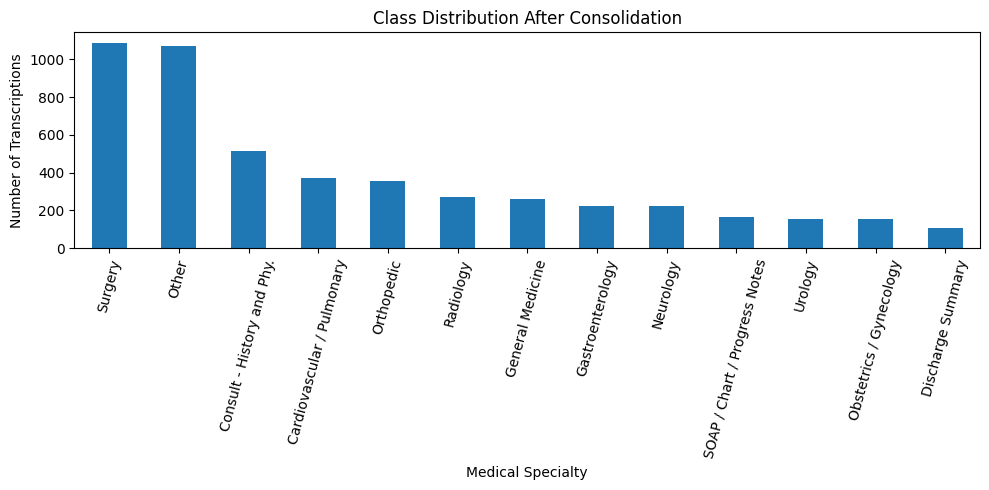

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
data["medical_specialty"].value_counts().plot(kind="bar")
plt.title("Class Distribution After Consolidation")
plt.xlabel("Medical Specialty")
plt.ylabel("Number of Transcriptions")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


## 3. Labels & Stratified Train/Val/Test Split

In [12]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
data["label"] = label_encoder.fit_transform(data["medical_specialty"])

print("Label mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)


Label mapping:
0 = Cardiovascular / Pulmonary
1 = Consult - History and Phy.
2 = Discharge Summary
3 = Gastroenterology
4 = General Medicine
5 = Neurology
6 = Obstetrics / Gynecology
7 = Orthopedic
8 = Other
9 = Radiology
10 = SOAP / Chart / Progress Notes
11 = Surgery
12 = Urology


In [13]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data, test_size=0.20, random_state=42, stratify=data["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))


Training samples: 3972
Validation samples: 497
Testing samples: 497


## 4. Class Weights (fixes imbalance-driven accuracy loss)

We compute inverse-frequency class weights and feed them into the loss function via a
custom `Trainer` subclass. This stops the model from just predicting the majority class
to minimize loss.


In [14]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)
class_weights = np.array(class_weights, dtype=np.float32)
print("Class weights:")
for cls, w in zip(label_encoder.classes_, class_weights):
    print(f"  {cls:30s} -> {w:.3f}")


Class weights:
  Cardiovascular / Pulmonary     -> 1.029
  Consult - History and Phy.     -> 0.740
  Discharge Summary              -> 3.553
  Gastroenterology               -> 1.707
  General Medicine               -> 1.476
  Neurology                      -> 1.717
  Obstetrics / Gynecology        -> 2.464
  Orthopedic                     -> 1.076
  Other                          -> 0.356
  Radiology                      -> 1.402
  SOAP / Chart / Progress Notes  -> 2.297
  Surgery                        -> 0.351
  Urology                        -> 2.444


## 5. Tokenization (longer max length)

In [15]:
!pip install -q transformers datasets accelerate
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [16]:
from transformers import AutoTokenizer

MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
MAX_LENGTH = 384  # was 256 — captures more of the note before truncating

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded. Model max length:", tokenizer.model_max_length)


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Tokenizer loaded. Model max length: 1000000000000000019884624838656


In [17]:
from datasets import Dataset

def to_dataset(frame):
    return Dataset.from_pandas(
        frame[["transcription", "label"]].reset_index(drop=True),
        preserve_index=False
    )

train_dataset = to_dataset(train_df)
val_dataset = to_dataset(val_df)
test_dataset = to_dataset(test_df)

def tokenize_function(examples):
    texts = [str(t) if t is not None else "" for t in examples["transcription"]]
    return tokenizer(texts, truncation=True, max_length=MAX_LENGTH)

tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=["transcription"])
tokenized_val = val_dataset.map(tokenize_function, batched=True, remove_columns=["transcription"])
tokenized_test = test_dataset.map(tokenize_function, batched=True, remove_columns=["transcription"])

tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_val = tokenized_val.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

print(tokenized_train)


Map:   0%|          | 0/3972 [00:00<?, ? examples/s]

Map:   0%|          | 0/497 [00:00<?, ? examples/s]

Map:   0%|          | 0/497 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3972
})


In [18]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Data collator ready.")


Data collator ready.


### Version-safe `TrainingArguments` builder

Different `transformers` versions rename or drop a few `TrainingArguments` fields
(e.g. `evaluation_strategy` -> `eval_strategy`, or `warmup_ratio` missing in some
older/forked installs). This helper inspects whatever version is actually installed
and only passes the arguments it supports, so the notebook won't break with a
`TypeError: unexpected keyword argument` again.


In [19]:
import inspect
from transformers import TrainingArguments

def make_training_args(**kwargs):
    """Build TrainingArguments using only kwargs supported by the installed version."""
    valid_params = set(inspect.signature(TrainingArguments.__init__).parameters.keys())

    # handle the evaluation_strategy / eval_strategy rename across versions
    if "eval_strategy" in kwargs and "eval_strategy" not in valid_params and "evaluation_strategy" in valid_params:
        kwargs["evaluation_strategy"] = kwargs.pop("eval_strategy")
    elif "eval_strategy" not in valid_params:
        kwargs.pop("eval_strategy", None)

    dropped = [k for k in kwargs if k not in valid_params]
    if dropped:
        print("Note: this transformers version does not support these args, skipping:", dropped)

    filtered = {k: v for k, v in kwargs.items() if k in valid_params}
    return TrainingArguments(**filtered)

print("make_training_args() ready.")


make_training_args() ready.


## 6. Model, Weighted Loss Trainer & Metrics

In [20]:
from transformers import AutoModelForSequenceClassification

num_labels = len(label_encoder.classes_)

def create_model():
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_labels)

model = create_model()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("Model running on:", device, "| classes:", num_labels)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Model running on: cuda | classes: 13


In [21]:
import torch.nn as nn
from transformers import Trainer

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

class WeightedTrainer(Trainer):
    """Trainer that applies class-weighted CrossEntropyLoss to counter class imbalance."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


In [22]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted", zero_division=0
    )
    accuracy = accuracy_score(labels, predictions)
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


## 7. Centralized Training (baseline)

 **We are running 4 epochs**


In [23]:
import datasets
datasets.config.TORCHVISION_AVAILABLE = False

In [24]:
!pip install -q "torchvision<0.20" --force-reinstall

ERROR: Ignored the following yanked versions: 0.1.6, 0.1.7, 0.1.8, 0.1.9, 0.2.0, 0.2.1, 0.2.2, 0.2.2.post2, 0.2.2.post3
ERROR: Could not find a version that satisfies the requirement torchvision<0.20 (from versions: 0.21.0, 0.22.0, 0.22.1, 0.23.0, 0.24.0, 0.24.1, 0.25.0, 0.26.0, 0.27.0, 0.27.1, 0.28.0, 0.29.0, 0.29.1, 0.29.2)
ERROR: No matching distribution found for torchvision<0.20


In [25]:
training_args = make_training_args(
    output_dir="./clinicalbert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    warmup_ratio=0.1,
    lr_scheduler_type="cosine",
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print("Starting training...")
trainer.train()





Note: this transformers version does not support these args, skipping: ['warmup_ratio']
Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.731394,1.519998,0.374245,0.428285,0.374245,0.328871
2,1.251173,1.333814,0.366197,0.381429,0.366197,0.321338
3,1.091498,1.323222,0.364185,0.390313,0.364185,0.322620
4,1.075729,1.330623,0.364185,0.399563,0.364185,0.324850


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1988, training_loss=1.401771157800072, metrics={'train_runtime': 399.7629, 'train_samples_per_second': 39.744, 'train_steps_per_second': 4.973, 'total_flos': 3135540985417728.0, 'train_loss': 1.401771157800072, 'epoch': 4.0})

In [26]:
test_results = trainer.evaluate(tokenized_test)
print("\nCentralized Test Results")
print("=" * 40)
for k, v in test_results.items():
    if isinstance(v, (int, float)):
        print(f"{k}: {v:.4f}")


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
1.075729,1.490003,4,0.362173,0.401604,0.362173,0.315492



Centralized Test Results
eval_loss: 1.4900
eval_accuracy: 0.3622
eval_precision: 0.4016
eval_recall: 0.3622
eval_f1: 0.3155


In [27]:
from sklearn.metrics import classification_report
import numpy as np

predictions = trainer.predict(tokenized_test)
predicted_labels = np.argmax(predictions.predictions, axis=1)
true_labels = predictions.label_ids

print(classification_report(
    true_labels, predicted_labels,
    target_names=label_encoder.classes_, zero_division=0
))


                               precision    recall  f1-score   support

   Cardiovascular / Pulmonary       0.41      0.65      0.50        37
   Consult - History and Phy.       0.30      0.41      0.34        51
            Discharge Summary       0.44      0.64      0.52        11
             Gastroenterology       0.32      0.73      0.44        22
             General Medicine       0.22      0.38      0.28        26
                    Neurology       0.31      0.35      0.33        23
      Obstetrics / Gynecology       0.45      0.88      0.60        16
                   Orthopedic       0.34      0.72      0.46        36
                        Other       0.52      0.10      0.17       107
                    Radiology       0.44      0.52      0.47        27
SOAP / Chart / Progress Notes       0.25      0.24      0.24        17
                      Surgery       0.41      0.11      0.17       109
                      Urology       0.54      0.87      0.67        15

    

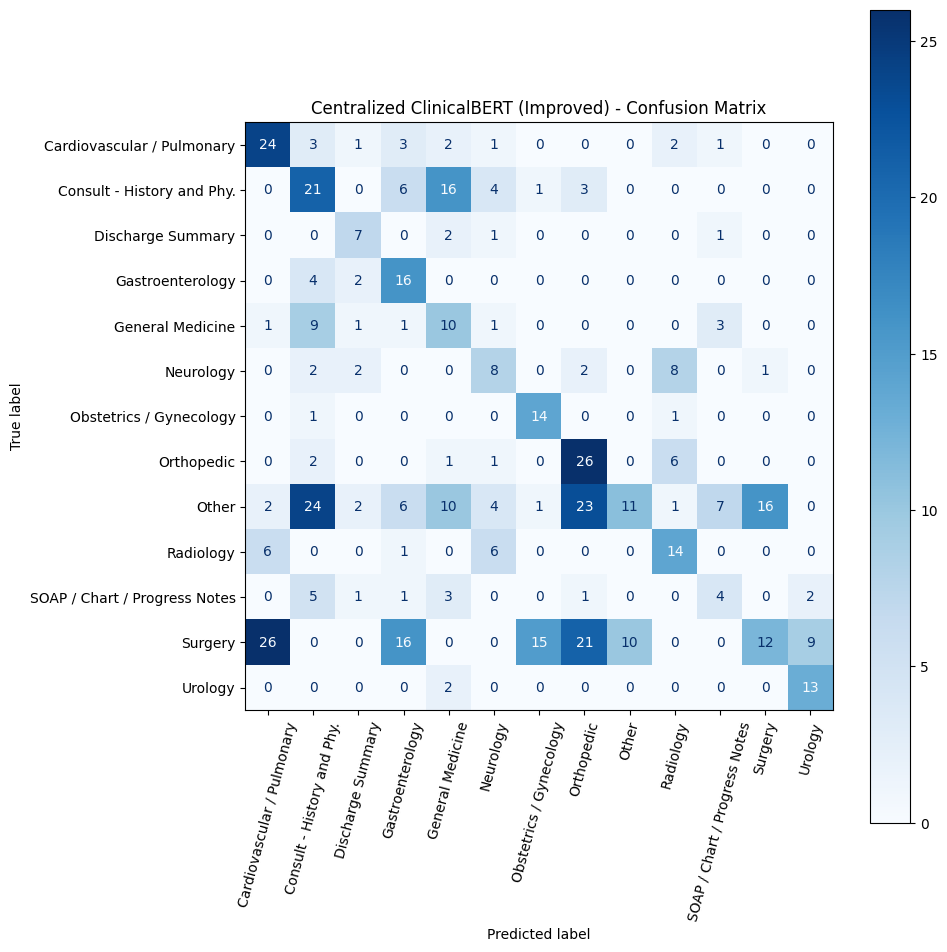

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, predicted_labels)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(ax=ax, xticks_rotation=75, cmap="Blues", values_format="d")
plt.title("Centralized ClinicalBERT (Improved) - Confusion Matrix")
plt.tight_layout()
plt.show()


In [29]:
import os, joblib

os.makedirs("./centralized_clinicalbert", exist_ok=True)
trainer.save_model("./centralized_clinicalbert")
tokenizer.save_pretrained("./centralized_clinicalbert")
joblib.dump(label_encoder, "./centralized_clinicalbert/label_encoder.pkl")
print("Centralized model saved.")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Centralized model saved.


## 8. Federated Learning Simulation (3 Hospitals)

**2 local epochs per round** and weighted loss, and we run **5 rounds**


In [30]:
import numpy as np

np.random.seed(42)
NUM_CLIENTS = 3
ALPHA = 0.5  # lower = more non-IID

client_data = {cid: [] for cid in range(NUM_CLIENTS)}

for label, group in train_df.groupby("label"):
    indices = group.index.to_numpy()
    np.random.shuffle(indices)
    proportions = np.random.dirichlet(np.repeat(ALPHA, NUM_CLIENTS))
    split_points = (np.cumsum(proportions) * len(indices)).astype(int)[:-1]
    splits = np.split(indices, split_points)
    for cid, idx in enumerate(splits):
        client_data[cid].extend(idx.tolist())

client_dfs = {cid: train_df.loc[idxs] for cid, idxs in client_data.items()}

for cid in range(NUM_CLIENTS):
    print(f"Hospital {cid+1}: {len(client_dfs[cid])} samples")


Hospital 1: 1140 samples
Hospital 2: 1270 samples
Hospital 3: 1562 samples


In [31]:
from datasets import Dataset

client_datasets = {}
tokenized_clients = {}

for cid in range(NUM_CLIENTS):
    client_datasets[cid] = Dataset.from_pandas(
        client_dfs[cid][["transcription", "label"]].reset_index(drop=True),
        preserve_index=False
    )
    tok = client_datasets[cid].map(tokenize_function, batched=True, remove_columns=["transcription"])
    tok = tok.rename_column("label", "labels")
    tok.set_format("torch")
    tokenized_clients[cid] = tok
    print(f"Hospital {cid+1} tokenized: {len(tok)} samples")


Map:   0%|          | 0/1140 [00:00<?, ? examples/s]

Hospital 1 tokenized: 1140 samples


Map:   0%|          | 0/1270 [00:00<?, ? examples/s]

Hospital 2 tokenized: 1270 samples


Map:   0%|          | 0/1562 [00:00<?, ? examples/s]

Hospital 3 tokenized: 1562 samples


In [32]:
def train_local_model(client_id, global_state_dict, epochs=2):
    print(f"\n--- Local training: Hospital {client_id+1} ---")

    local_model = create_model()
    local_model.load_state_dict(global_state_dict)
    local_model.to(device)

    # class weights specific to this hospital's local data distribution
    local_labels = client_dfs[client_id]["label"].to_numpy()
    local_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(num_labels),
        y=np.concatenate([local_labels, np.arange(num_labels)])  # ensure all classes present
    )
    local_weights_tensor = torch.tensor(local_weights, dtype=torch.float32).to(device)

    class LocalWeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss_fct = nn.CrossEntropyLoss(weight=local_weights_tensor)
            loss = loss_fct(outputs.logits.view(-1, num_labels), labels.view(-1))
            return (loss, outputs) if return_outputs else loss

    local_args = make_training_args(
        output_dir=f"./fed_hospital_{client_id}",
        num_train_epochs=epochs,
        per_device_train_batch_size=8,
        learning_rate=2e-5,
        weight_decay=0.01,
        logging_steps=100,
        report_to="none",
        fp16=torch.cuda.is_available(),
        save_strategy="no",
    )

    local_trainer = LocalWeightedTrainer(
        model=local_model,
        args=local_args,
        train_dataset=tokenized_clients[client_id],
        data_collator=data_collator,
    )
    local_trainer.train()

    return local_model.state_dict(), len(tokenized_clients[client_id])


In [33]:
from collections import OrderedDict

def fedavg(client_states, client_sizes):
    total_samples = sum(client_sizes)
    global_state = OrderedDict()
    for key in client_states[0].keys():
        weighted_sum = torch.zeros_like(client_states[0][key], dtype=torch.float32)
        for state_dict, n in zip(client_states, client_sizes):
            weight = n / total_samples
            weighted_sum += state_dict[key].float() * weight
        # cast back to original dtype if needed
        global_state[key] = weighted_sum.to(client_states[0][key].dtype)
    return global_state

print("FedAvg function ready.")


FedAvg function ready.


In [34]:
federated_eval_args = make_training_args(
    output_dir="./federated_evaluation",
    per_device_eval_batch_size=8,
    report_to="none",
    fp16=False,
)

def evaluate_global_model(global_model):
    federated_trainer = Trainer(
        model=global_model,
        args=federated_eval_args,
        eval_dataset=tokenized_test,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )
    return federated_trainer.evaluate(tokenized_test)


In [35]:
federated_eval_args = make_training_args(
    output_dir="./federated_evaluation",
    per_device_eval_batch_size=8,
    report_to="none",
    fp16=torch.cuda.is_available(),   # was fp16=False
)

In [36]:
NUM_ROUNDS = 5
LOCAL_EPOCHS = 2

global_model = create_model()
global_model.to(device)
global_state_dict = global_model.state_dict()

federated_history = []

for round_num in range(1, NUM_ROUNDS + 1):
    print("\n" + "=" * 60)
    print(f"FEDERATED ROUND {round_num}")
    print("=" * 60)

    client_states, client_sizes = [], []
    for cid in range(NUM_CLIENTS):
        state_dict, n_samples = train_local_model(cid, global_state_dict, epochs=LOCAL_EPOCHS)
        client_states.append(state_dict)
        client_sizes.append(n_samples)

    global_state_dict = fedavg(client_states, client_sizes)
    global_model.load_state_dict(global_state_dict)

    results = evaluate_global_model(global_model)
    federated_history.append({
        "round": round_num,
        "accuracy": results["eval_accuracy"],
        "precision": results["eval_precision"],
        "recall": results["eval_recall"],
        "f1": results["eval_f1"],
        "loss": results["eval_loss"],
    })
    print(f"Round {round_num} -> Accuracy: {results['eval_accuracy']:.4f} | F1: {results['eval_f1']:.4f}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec


FEDERATED ROUND 1

--- Local training: Hospital 1 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Step,Training Loss
100,2.361978
200,1.975349


... (58 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Step,Training Loss
100,0.757007
200,0.713958
300,0.617083


Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,1.697029,0,0.338028,0.374831,0.338028,0.319527


Round 5 -> Accuracy: 0.3380 | F1: 0.3195


In [37]:
import pandas as pd

federated_history_df = pd.DataFrame(federated_history).sort_values("round").reset_index(drop=True)
print(federated_history_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


 round  accuracy  precision  recall     f1   loss
     1    0.3702     0.2149  0.3702 0.2670 2.0413
     2    0.3722     0.2663  0.3722 0.2947 1.7353
     3    0.3622     0.3997  0.3622 0.3091 1.6145
     4    0.3501     0.3787  0.3501 0.3161 1.6187
     5    0.3380     0.3748  0.3380 0.3195 1.6970


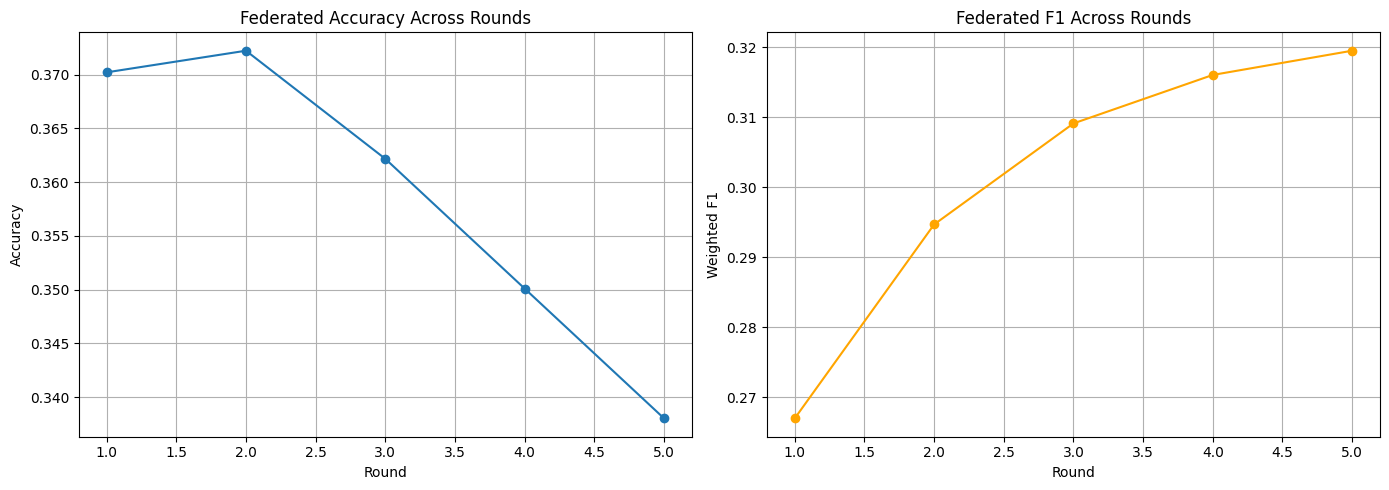

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(federated_history_df["round"], federated_history_df["accuracy"], marker="o")
axes[0].set_title("Federated Accuracy Across Rounds")
axes[0].set_xlabel("Round"); axes[0].set_ylabel("Accuracy"); axes[0].grid(True)

axes[1].plot(federated_history_df["round"], federated_history_df["f1"], marker="o", color="orange")
axes[1].set_title("Federated F1 Across Rounds")
axes[1].set_xlabel("Round"); axes[1].set_ylabel("Weighted F1"); axes[1].grid(True)

plt.tight_layout()
plt.show()


In [39]:
import os, joblib

FEDERATED_MODEL_PATH = "./federated_clinicalbert"
os.makedirs(FEDERATED_MODEL_PATH, exist_ok=True)
global_model.save_pretrained(FEDERATED_MODEL_PATH)
tokenizer.save_pretrained(FEDERATED_MODEL_PATH)
joblib.dump(label_encoder, os.path.join(FEDERATED_MODEL_PATH, "label_encoder.pkl"))
print("Federated model saved:", FEDERATED_MODEL_PATH)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Federated model saved: ./federated_clinicalbert


## 9. Differential Privacy (Opacus, DP-SGD)




In [40]:
!pip install -q opacus
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
print("Opacus ready.")


Opacus ready.


In [41]:
DP_DELTA = 1e-5
DP_NOISE_MULTIPLIER = 0.8   # was 1.0 - slightly less noise, still private
DP_MAX_GRAD_NORM = 1.0
DP_LOCAL_EPOCHS = 1
DP_BATCH_SIZE = 8

print("DP config -> noise:", DP_NOISE_MULTIPLIER, "| clip:", DP_MAX_GRAD_NORM)


DP config -> noise: 0.8 | clip: 1.0


In [42]:
from torch.utils.data import DataLoader

def train_dp_local_model(client_id, global_state_dict):
    print(f"\n--- DP local training: Hospital {client_id+1} ---")

    dp_model = create_model()
    dp_model.load_state_dict(global_state_dict)

    # Freeze everything except last encoder layer + pooler + classifier
    for p in dp_model.parameters():
        p.requires_grad = False
    for p in dp_model.bert.encoder.layer[-1].parameters():
        p.requires_grad = True
    for p in dp_model.bert.pooler.parameters():
        p.requires_grad = True
    for p in dp_model.classifier.parameters():
        p.requires_grad = True

    dp_model.to(device)
    dp_model.train()

    errors = ModuleValidator.validate(dp_model, strict=False)
    if errors:
        dp_model = ModuleValidator.fix(dp_model)
        dp_model.to(device)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, dp_model.parameters()), lr=2e-5
    )

    loader = DataLoader(
        tokenized_clients[client_id], batch_size=DP_BATCH_SIZE,
        shuffle=True, collate_fn=data_collator
    )

    privacy_engine = PrivacyEngine()
    dp_model, optimizer, loader = privacy_engine.make_private(
        module=dp_model,
        optimizer=optimizer,
        data_loader=loader,
        noise_multiplier=DP_NOISE_MULTIPLIER,
        max_grad_norm=DP_MAX_GRAD_NORM,
    )

    for epoch in range(DP_LOCAL_EPOCHS):
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            outputs = dp_model(**batch)
            outputs.loss.backward()
            optimizer.step()

    epsilon = privacy_engine.get_epsilon(delta=DP_DELTA)
    print(f"Hospital {client_id+1} finished. epsilon = {epsilon:.2f}")

    # unwrap GradSampleModule to get a clean state_dict
    state_dict = dp_model._module.state_dict() if hasattr(dp_model, "_module") else dp_model.state_dict()
    return state_dict, len(tokenized_clients[client_id]), epsilon


In [43]:
dp_state_1, dp_size_1, dp_epsilon_1 = train_dp_local_model(0, global_model.state_dict())
dp_state_2, dp_size_2, dp_epsilon_2 = train_dp_local_model(1, global_model.state_dict())
dp_state_3, dp_size_3, dp_epsilon_3 = train_dp_local_model(2, global_model.state_dict())



--- DP local training: Hospital 1 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Hospital 1 finished. epsilon = 1.23

--- DP local training: Hospital 2 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Hospital 2 finished. epsilon = 1.15

--- DP local training: Hospital 3 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Hospital 3 finished. epsilon = 1.01


In [44]:
dp_client_states = [dp_state_1, dp_state_2, dp_state_3]
dp_client_sizes = [dp_size_1, dp_size_2, dp_size_3]

dp_global_state = fedavg(dp_client_states, dp_client_sizes)

dp_federated_model = create_model()
dp_federated_model.load_state_dict(dp_global_state)
dp_federated_model.to(device)
print("DP-Federated model aggregated.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

DP-Federated model aggregated.


In [45]:
dp_eval_trainer = Trainer(
    model=dp_federated_model,
    args=federated_eval_args,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
dp_test_results = dp_eval_trainer.evaluate()
print("\nDP-Federated Test Results:")
for k, v in dp_test_results.items():
    if isinstance(v, (int, float)):
        print(f"{k}: {v:.4f}")


Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,1.694617,0,0.334004,0.369886,0.334004,0.316320



DP-Federated Test Results:
eval_loss: 1.6946
eval_accuracy: 0.3340
eval_precision: 0.3699
eval_recall: 0.3340
eval_f1: 0.3163


## 10. Final Comparison — Centralized vs Federated vs DP-Federated

In [46]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Centralized ClinicalBERT", "Federated ClinicalBERT", "DP-Federated ClinicalBERT"],
    "Accuracy": [test_results["eval_accuracy"], federated_history_df.iloc[-1]["accuracy"], dp_test_results["eval_accuracy"]],
    "Precision": [test_results["eval_precision"], federated_history_df.iloc[-1]["precision"], dp_test_results["eval_precision"]],
    "Recall": [test_results["eval_recall"], federated_history_df.iloc[-1]["recall"], dp_test_results["eval_recall"]],
    "Weighted_F1": [test_results["eval_f1"], federated_history_df.iloc[-1]["f1"], dp_test_results["eval_f1"]],
})
comparison[["Accuracy","Precision","Recall","Weighted_F1"]] = (comparison[["Accuracy","Precision","Recall","Weighted_F1"]] * 100).round(2)
comparison


,Model,Accuracy,Precision,Recall,Weighted_F1
0,Centralized ClinicalBERT,36.22,40.16,36.22,31.55
1,Federated ClinicalBERT,33.80,37.48,33.80,31.95
2,DP-Federated ClinicalBERT,33.40,36.99,33.40,31.63


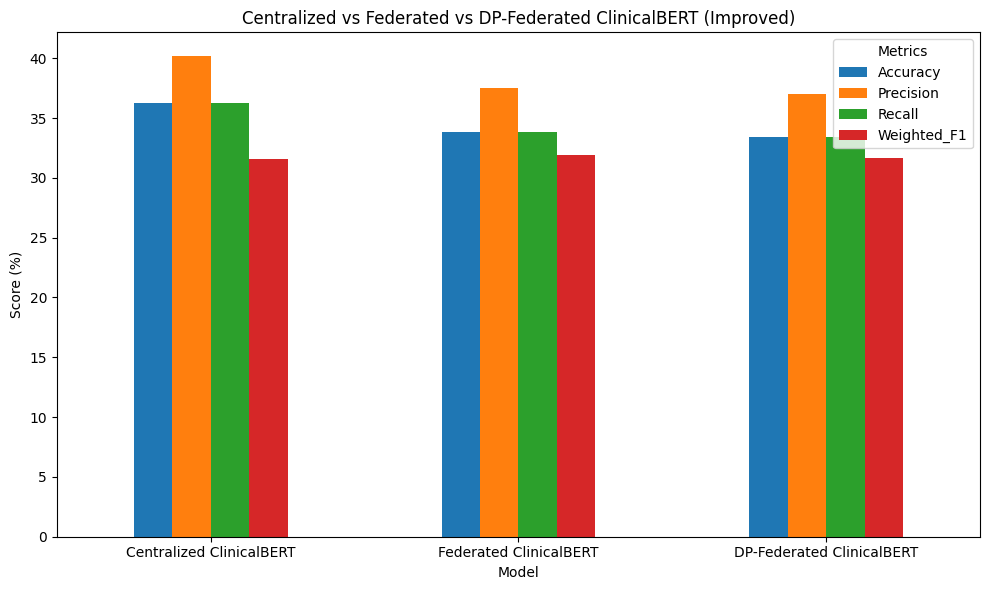

In [47]:
import matplotlib.pyplot as plt

comparison.set_index("Model")[["Accuracy","Precision","Recall","Weighted_F1"]].plot(kind="bar", figsize=(10,6))
plt.title("Centralized vs Federated vs DP-Federated ClinicalBERT (Improved)")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()


In [48]:
privacy_results = pd.DataFrame({
    "Hospital": ["Hospital 1", "Hospital 2", "Hospital 3"],
    "Samples": [dp_size_1, dp_size_2, dp_size_3],
    "Epsilon": [dp_epsilon_1, dp_epsilon_2, dp_epsilon_3],
    "Delta": [DP_DELTA, DP_DELTA, DP_DELTA],
})
privacy_results


,Hospital,Samples,Epsilon,Delta
0,Hospital 1,1140,1.232592,0.00001
1,Hospital 2,1270,1.154684,0.00001
2,Hospital 3,1562,1.011084,0.00001


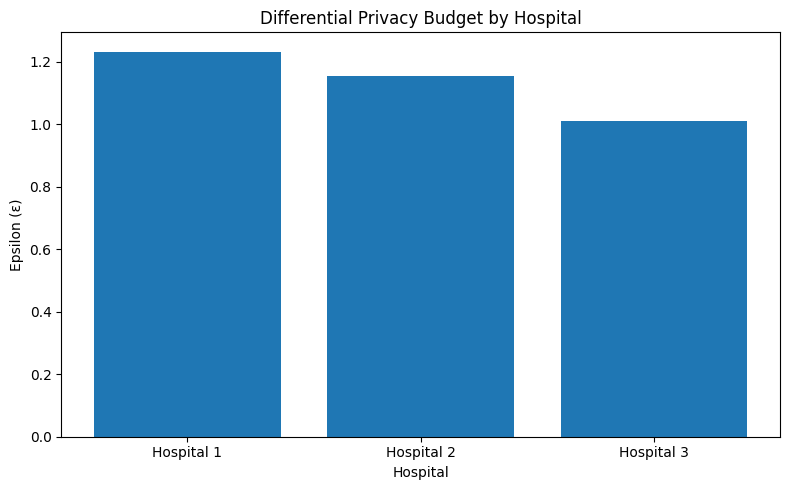

In [49]:
plt.figure(figsize=(8,5))
plt.bar(privacy_results["Hospital"], privacy_results["Epsilon"])
plt.title("Differential Privacy Budget by Hospital")
plt.xlabel("Hospital"); plt.ylabel("Epsilon (ε)")
plt.tight_layout()
plt.show()


In [50]:
import os, joblib

FINAL_MODEL_PATH = "./final_dp_federated_clinicalbert"
os.makedirs(FINAL_MODEL_PATH, exist_ok=True)
dp_federated_model.save_pretrained(FINAL_MODEL_PATH)
tokenizer.save_pretrained(FINAL_MODEL_PATH)
joblib.dump(label_encoder, os.path.join(FINAL_MODEL_PATH, "label_encoder.pkl"))
comparison.to_csv("final_results.csv", index=False)
privacy_results.to_csv("privacy_results.csv", index=False)
print("Final model + results saved.")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model + results saved.


## 11. Demo Interface (Gradio)

Fixes the gap from the first version: the demo now also shows the **privacy-budget
indicator (ε)**, matching Objective 5 of the proposal (predicted category,
confidence score, AND privacy-budget indicator).


In [51]:
def predict_specialty(text, model_to_use=None, tok=None):
    model_to_use = model_to_use or dp_federated_model
    tok = tok or tokenizer

    inputs = tok(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    model_to_use.eval()
    with torch.no_grad():
        outputs = model_to_use(**inputs)

    probs = torch.softmax(outputs.logits, dim=-1)
    predicted_id = torch.argmax(probs, dim=-1).item()
    confidence = probs[0][predicted_id].item()

    return label_encoder.classes_[predicted_id], confidence


In [52]:
!pip install -q gradio
import gradio as gr

# Average epsilon across the 3 hospitals, shown as the privacy-budget indicator
AVG_EPSILON = float(privacy_results["Epsilon"].mean())

def classify_medical_transcription(text):
    if not text or not text.strip():
        return "Please enter a medical transcription.", "0.00%", "-"

    specialty, confidence = predict_specialty(text)

    if AVG_EPSILON < 3:
        privacy_level = f"ε = {AVG_EPSILON:.2f} (Strong privacy)"
    elif AVG_EPSILON < 8:
        privacy_level = f"ε = {AVG_EPSILON:.2f} (Moderate privacy)"
    else:
        privacy_level = f"ε = {AVG_EPSILON:.2f} (Weak privacy)"

    return specialty, f"{confidence*100:.2f}%", privacy_level

interface = gr.Interface(
    fn=classify_medical_transcription,
    inputs=gr.Textbox(lines=10, placeholder="Enter medical transcription here...", label="Medical Transcription"),
    outputs=[
        gr.Textbox(label="Predicted Medical Specialty"),
        gr.Textbox(label="Confidence"),
        gr.Textbox(label="Privacy-Budget Indicator"),
    ],
    title="Privacy-Preserving Medical Specialty Classifier",
    description="DP-Federated ClinicalBERT — trained across 3 simulated hospitals without sharing raw patient data.",
)

interface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b43ca175f885d6d638.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
